# **CVC-ClinicDB Dataset**

In [2]:
import torch
from segmentation_models import *

if torch.cuda.is_available():
    device = torch.device("cuda")
    print("CUDA device found.")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
    print("MPS device found.")
else:
    device = torch.device("cpu")
    print("Using CPU.")

CUDA device found.


In [3]:
# Dataset Paths
dataset_path = "data/CVC-ClinicDB"
image_dir = "Original"
mask_dir = "Ground Truth"

# Image Preprocessing Parameters
IMG_SIZE = (256, 256)  # Changed to (256, 256) as per the context

dataset = MedicalImageSegmentationData(
    dataset_path=dataset_path,
    image_dir=image_dir,
    mask_dir=mask_dir,
    img_size=IMG_SIZE,
    batch_size=8,
    test_size=0.1,
    random_state=42,
    binarize_mask=True,
)

train_loader, test_loader = dataset.dataloaders()

print(f"Total number of samples: {len(dataset)}")
print(f"Number of training samples: {len(train_loader.dataset)}")
print(f"Number of testing samples: {len(test_loader.dataset)}")

# dataset.visualize_samples()

Total number of samples: 612
Number of training samples: 550
Number of testing samples: 62


# Unet CVC model training config

In [4]:
cfg = TrainConfig(
    # --- General ---
    model_name = "SCAInceptionUNet",
    dataset_name = "CVC-ClinicDB",
    criterion = "BCEDiceLoss",
    optimizer = "AdamW",
    epochs = 100,
    lr = 1e-3,
    weight_decay = 1e-4,

    # --- Scheduler ---
    scheduler = "ReduceLROnPlateau",
    scheduler_factor = 0.5,          # for ReduceLROnPlateau
    scheduler_patience = 5,            # for ReduceLROnPlateau
    mode = "min",

    # --- Training control ---
    early_stopping_patience = 10,

    # --- Paths / logging ---
    base_dir="model_comparisons",
    models_dir = "trained_models",
    history_dir = "models_history",
    loss_dir = "loss_plots",
    visualize_dir = "visualizations",
    logs_dir = "logs",
    use_wandb = True,
    wandb_project = "segmentation_models",
    wandb_run_name = None,
    wandb_watch_log_freq = 100,

    # --- Metrics ---
    threshold = 0.5,
    log_train_metrics = True
)

In [5]:
if cfg.use_wandb:
    from dotenv import load_dotenv
    load_dotenv()
    import wandb
    wandb.login(key=os.getenv("WANDB_API_KEY"))

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: Appending key for api.wandb.ai to your netrc file: /home/humblebee/.netrc
wandb: Currently logged in as: mironshoh (iv-drip-counter) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


In [6]:
model = SCA_InceptionUNeXt(in_channels=3, out_channels=1)
trainer = SegmentationTrainer(model, device, train_loader, test_loader, test_loader, cfg=cfg)
result = trainer.train()
result


2025-09-08 08:13:35 | INFO | SCAInceptionUNet_model_CVC_ClinicDB_20250908_081335 | Logging to model_comparisons/logs/SCAInceptionUNet_model_CVC_ClinicDB_20250908_081335.log
wandb: WARNING Using a boolean value for 'reinit' is deprecated. Use 'return_previous' or 'finish_previous' instead.


2025-09-08 08:13:36 | INFO | SCAInceptionUNet_model_CVC_ClinicDB_20250908_081335 | W&B URL: https://wandb.ai/iv-drip-counter/segmentation_models/runs/izxkozfp
100%|██████████| 8/8 [00:00<00:00,  9.77it/s]
2025-09-08 08:13:51 | INFO | SCAInceptionUNet_model_CVC_ClinicDB_20250908_081335 | Epoch 001/100 | Train: 1.008008 | Val: 1.025499 | LR: 0.001000 | 14.52s | Val Dice: 0.2173 IoU: 0.1498 F1: 0.2625
2025-09-08 08:13:51 | INFO | SCAInceptionUNet_model_CVC_ClinicDB_20250908_081335 | Saved best: model_comparisons/models/best_SCAInceptionUNet_model_CVC_ClinicDB_20250908_081335.pth (val=1.025499)
100%|██████████| 8/8 [00:01<00:00,  6.74it/s]
2025-09-08 08:14:06 | INFO | SCAInceptionUNet_model_CVC_ClinicDB_20250908_081335 | Epoch 002/100 | Train: 0.808202 | Val: 0.948026 | LR: 0.001000 | 14.27s | Val Dice: 0.4162 IoU: 0.2954 F1: 0.4779
2025-09-08 08:14:06 | INFO | SCAInceptionUNet_model_CVC_ClinicDB_20250908_081335 | Saved best: model_comparisons/models/best_SCAInceptionUNet_model_CVC_ClinicD

avg_flops,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
avg_fps,▇▅█▅▅▆██▃█▇█▄▂▇▇▆▇▆▃▂▆▅▇▅▃▂▇▄█▇▅▇▁▇▆███▇
avg_gflops,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
avg_inference_time,▁▄▁▃▄▂▁▁▆▁▂▁▅▇▂▂▃▂▃▆▇▃▄▂▃▅▇▂▅▁▂▄▂█▂▃▁▁▁▂
epoch_seconds,▇▆▅▃▄▅▁█▂▁▁▃▇█▃▃▄▄▅▆▇▅▅▅▄▆▅▄▄▃▃▄▆▇▆▃▃▂▃▂
lr,██████████████████████████▃▃▃▃▃▃▃▃▃▁▁▁▁▁
num_trainable,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
train/dice,▁▂▃▄▄▅▅▅▆▆▆▇▆▇▇▇▇▇▇▇▇▇▇▇▇▇██████████████
train/f1,▁▂▃▄▄▅▅▅▆▆▆▇▆▇▇▇▇▇▇▇▇▇▇▇▇▇██████████████
train/iou,▁▂▂▃▃▄▄▅▅▅▆▆▆▆▆▇▇▇▇▇▇▇▇▇▇▇▇▇████████████
+11,...


{'best_val_loss': 0.2827781867235899,
 'epochs_ran': 40,
 'best_model_path': 'model_comparisons/models/best_SCAInceptionUNet_model_CVC_ClinicDB_20250908_081335.pth',
 'loss_csv_path': 'model_comparisons/history/loss_history_SCAInceptionUNet_CVC_ClinicDB_20250908_081335.csv',
 'wandb_url': 'https://wandb.ai/iv-drip-counter/segmentation_models/runs/izxkozfp',
 'log_path': 'model_comparisons/logs/SCAInceptionUNet_model_CVC_ClinicDB_20250908_081335.log'}

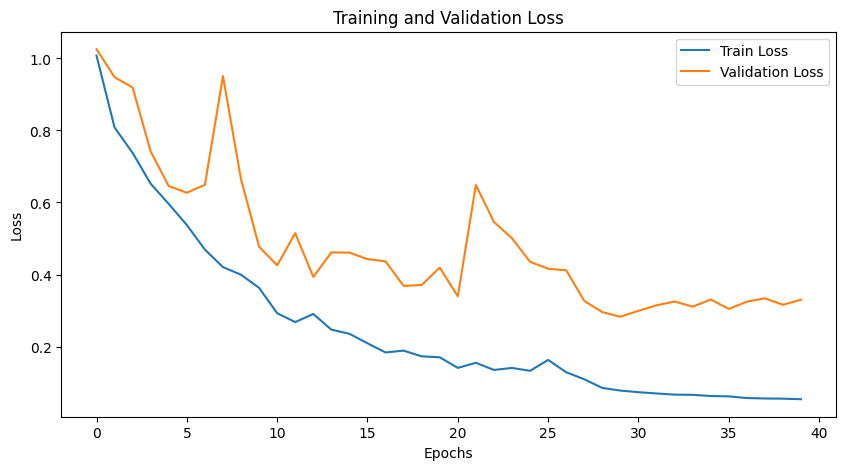

In [7]:
trainer.plot_losses()

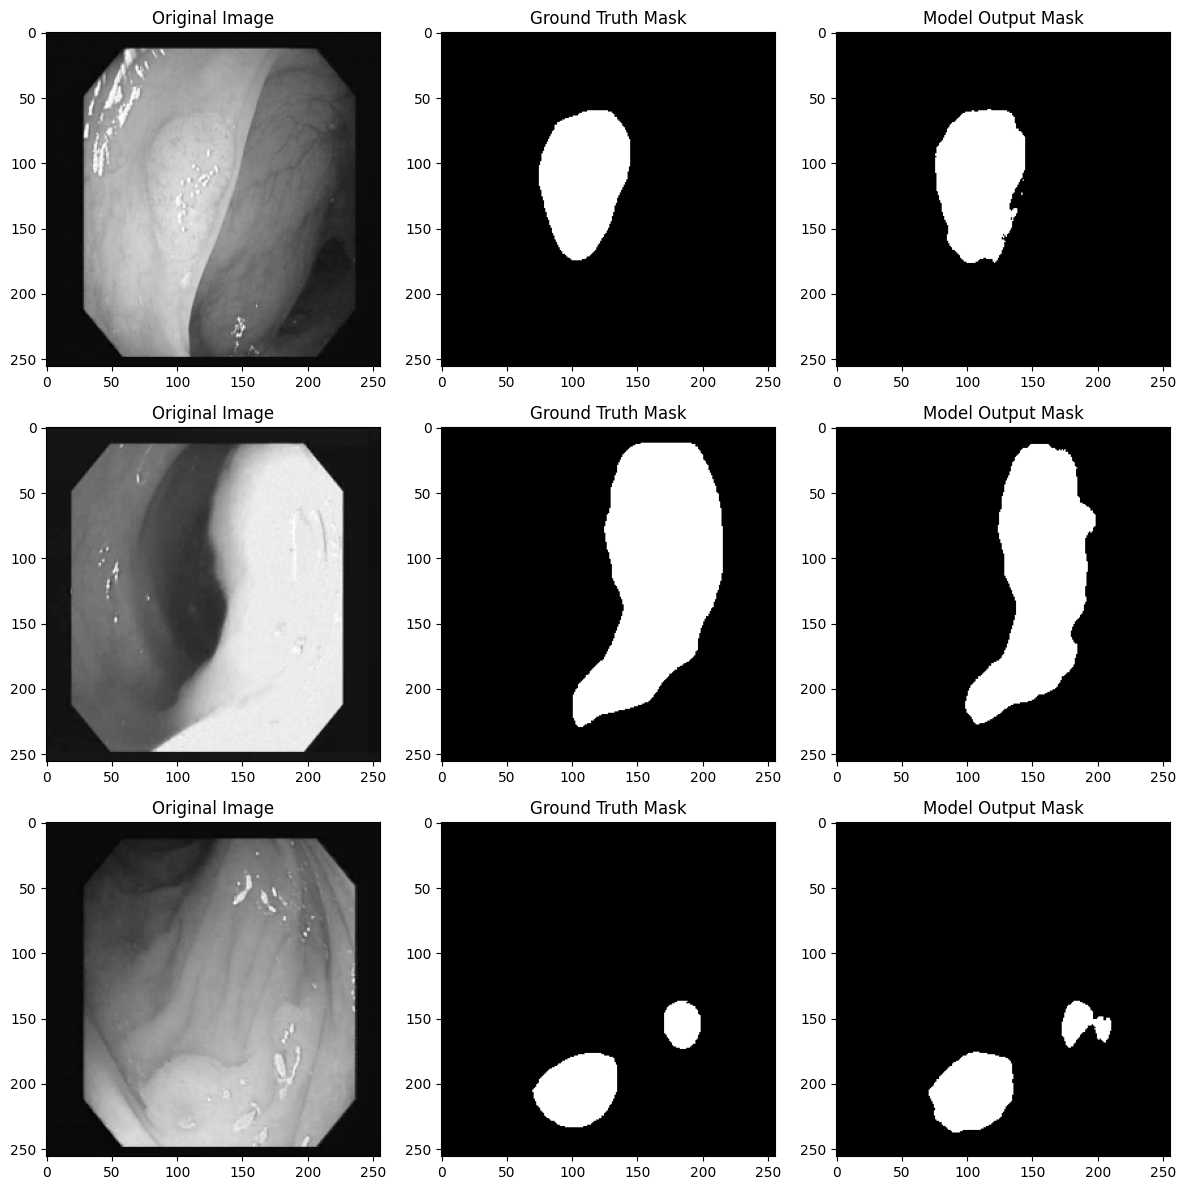

In [8]:
trainer.visualize_output_samples()

In [9]:
trainer.validate_and_save()

100%|██████████| 8/8 [00:00<00:00,  9.16it/s]



MODEL EVALUATION RESULTS
Test Loss                          : 0.3302
Average Dice Score                 : 0.7959
Average Hausdorff Distance         : 38.6937
Average IoU                        : 0.7055
Precision                          : 0.8954
Recall                             : 0.7683
F1 Score                           : 0.8270
IoU (batch avg)                    : 0.6961
Dice (batch avg)                   : 0.8170
Total Parameters                   : 10,319,211
Trainable Parameters               : 10,319,211
Average Inference Time (seconds)   : 0.043792
FPS (Frames Per Second)            : 22.84
FLOPs                              : 24,904,328,640.0
GFLOPs                             : 24.9043

Results saved to: model_comparisons/evaluation_results/SCAInceptionUNet_model_CVC-ClinicDB_evaluation_results_20250908_081335.csv
Validation results saved to model_comparisons/evaluation_results/SCAInceptionUNet_model_CVC-ClinicDB_evaluation_results


{'test_loss': 0.3302106950432062,
 'avg_dice_score': 0.7958965783022465,
 'avg_hd_score': 38.69367058046402,
 'avg_iou': 0.7054573768118937,
 'precision': 0.895372058985327,
 'recall': 0.7682913222963172,
 'f1': 0.8269780905017783,
 'iou_batch_avg': 0.696135513484478,
 'dice_batch_avg': 0.817030243575573,
 'total_params': 10319211,
 'trainable_params': 10319211,
 'avg_inference_time': 0.04379165172576904,
 'fps': 22.835402653048448,
 'flops': 24904328640.0,
 'gflops': 24.90432864}

# **Kvasir-SEG dataset**

In [10]:
import torch
from segmentation_models import *

if torch.cuda.is_available():
    device = torch.device("cuda")
    print("CUDA device found.")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
    print("MPS device found.")
else:
    device = torch.device("cpu")
    print("Using CPU.")


CUDA device found.


In [11]:
# Dataset Paths
dataset_path = "data/Kvasir-SEG"
image_dir = "images"
mask_dir = "masks"

# Image Preprocessing Parameters
IMG_SIZE = (256, 256)  # Changed to (256, 256) as per the context

dataset = MedicalImageSegmentationData(
    dataset_path=dataset_path,
    image_dir=image_dir,
    mask_dir=mask_dir,
    img_size=IMG_SIZE,
    batch_size=8,
    test_size=0.1,
    random_state=42,
    binarize_mask=True,
)

train_loader, test_loader = dataset.dataloaders()

print(f"Total number of samples: {len(dataset)}")
print(f"Number of training samples: {len(train_loader.dataset)}")
print(f"Number of testing samples: {len(test_loader.dataset)}")

# dataset.visualize_samples()

Total number of samples: 1000
Number of training samples: 900
Number of testing samples: 100


# UNet Kvasir training config

In [12]:
cfg = TrainConfig(
    # --- General ---
    model_name = "SCAInceptionUNet",
    dataset_name = "Kvasir-SEG",
    criterion = "BCEDiceLoss",
    optimizer = "AdamW",
    epochs = 100,
    lr = 1e-3,
    weight_decay = 1e-4,

    # --- Scheduler ---
    scheduler = "ReduceLROnPlateau",
    scheduler_factor = 0.5,          # for ReduceLROnPlateau
    scheduler_patience = 5,            # for ReduceLROnPlateau
    mode = "min",

    # --- Training control ---
    early_stopping_patience = 10,

    # --- Paths / logging ---
    base_dir="model_comparisons",
    models_dir = "trained_models",
    history_dir = "models_history",
    loss_dir = "loss_plots",
    visualize_dir = "visualizations",
    logs_dir = "logs",
    use_wandb = True,
    wandb_project = "segmentation_models",
    wandb_run_name = None,
    wandb_watch_log_freq = 100,

    # --- Metrics ---
    threshold = 0.5,
    log_train_metrics = True
)

In [13]:
if cfg.use_wandb:
    from dotenv import load_dotenv
    load_dotenv()
    import wandb
    wandb.login(key=os.getenv("WANDB_API_KEY"))

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: Appending key for api.wandb.ai to your netrc file: /home/humblebee/.netrc


In [14]:
model = SCA_InceptionUNeXt(in_channels=3, out_channels=1)
trainer = SegmentationTrainer(model, device, train_loader, test_loader, test_loader, cfg=cfg)
result = trainer.train()
result


2025-09-08 08:23:19 | INFO | SCAInceptionUNet_model_Kvasir_SEG_20250908_082319 | Logging to model_comparisons/logs/SCAInceptionUNet_model_Kvasir_SEG_20250908_082319.log


2025-09-08 08:23:20 | INFO | SCAInceptionUNet_model_Kvasir_SEG_20250908_082319 | W&B URL: https://wandb.ai/iv-drip-counter/segmentation_models/runs/aln3yv1g
100%|██████████| 13/13 [00:03<00:00,  4.24it/s]
2025-09-08 08:23:44 | INFO | SCAInceptionUNet_model_Kvasir_SEG_20250908_082319 | Epoch 001/100 | Train: 0.969494 | Val: 0.886696 | LR: 0.001000 | 23.67s | Val Dice: 0.4116 IoU: 0.3048 F1: 0.4676
2025-09-08 08:23:44 | INFO | SCAInceptionUNet_model_Kvasir_SEG_20250908_082319 | Saved best: model_comparisons/models/best_SCAInceptionUNet_model_Kvasir_SEG_20250908_082319.pth (val=0.886696)
100%|██████████| 13/13 [00:03<00:00,  4.12it/s]
2025-09-08 08:24:08 | INFO | SCAInceptionUNet_model_Kvasir_SEG_20250908_082319 | Epoch 002/100 | Train: 0.779687 | Val: 0.720544 | LR: 0.001000 | 23.19s | Val Dice: 0.5872 IoU: 0.4599 F1: 0.6354
2025-09-08 08:24:08 | INFO | SCAInceptionUNet_model_Kvasir_SEG_20250908_082319 | Saved best: model_comparisons/models/best_SCAInceptionUNet_model_Kvasir_SEG_20250908

avg_flops,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
avg_fps,▃▅▇▆▆█▇▆▇█▅▆▆▆▆▆▆▆▆▆▇▆▇█▇▇▆▇▅▇▇▇▇▇▁▅▃▃▅
avg_gflops,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
avg_inference_time,▆▄▂▂▃▁▂▃▂▁▄▃▃▃▂▃▃▃▃▃▂▃▂▁▂▂▃▂▄▂▂▂▂▂█▄▆▆▄
epoch_seconds,▅▄▃▃▅▃▂▂▁▃▃▃▂▂▂▃▃▃▃▃▃▂▃▂▃▃█▄▃▄▅▃▃▃▅▆▅▇▆
lr,███████████████████▄▄▄▄▄▄▄▄▂▂▂▂▂▂▂▁▁▁▁▁
num_trainable,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
train/dice,▁▃▃▄▄▅▅▅▅▆▆▆▆▆▇▇▇▇▇▇███████████████████
train/f1,▁▃▃▄▄▅▅▅▅▆▆▆▆▆▇▇▇▇▇▇███████████████████
train/iou,▁▂▃▃▃▄▄▅▅▅▅▆▆▆▆▇▆▇▇▇▇██████▇███████████
+11,...


{'best_val_loss': 0.38470621980153596,
 'epochs_ran': 39,
 'best_model_path': 'model_comparisons/models/best_SCAInceptionUNet_model_Kvasir_SEG_20250908_082319.pth',
 'loss_csv_path': 'model_comparisons/history/loss_history_SCAInceptionUNet_Kvasir_SEG_20250908_082319.csv',
 'wandb_url': 'https://wandb.ai/iv-drip-counter/segmentation_models/runs/aln3yv1g',
 'log_path': 'model_comparisons/logs/SCAInceptionUNet_model_Kvasir_SEG_20250908_082319.log'}

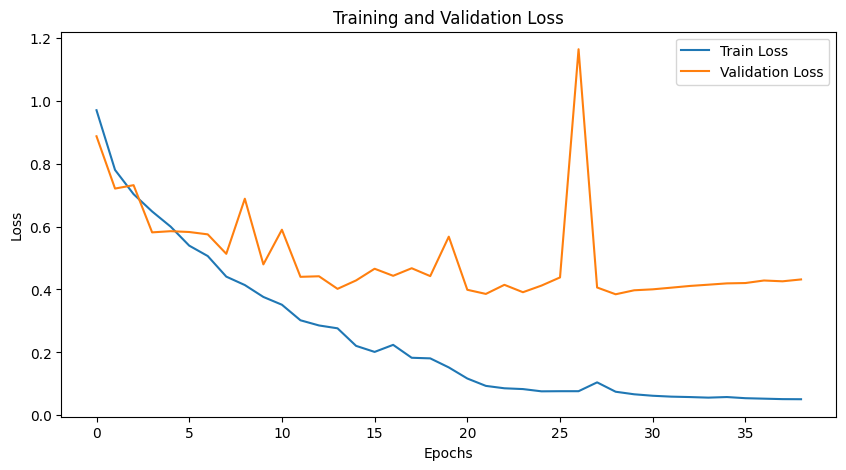

In [15]:
trainer.plot_losses()

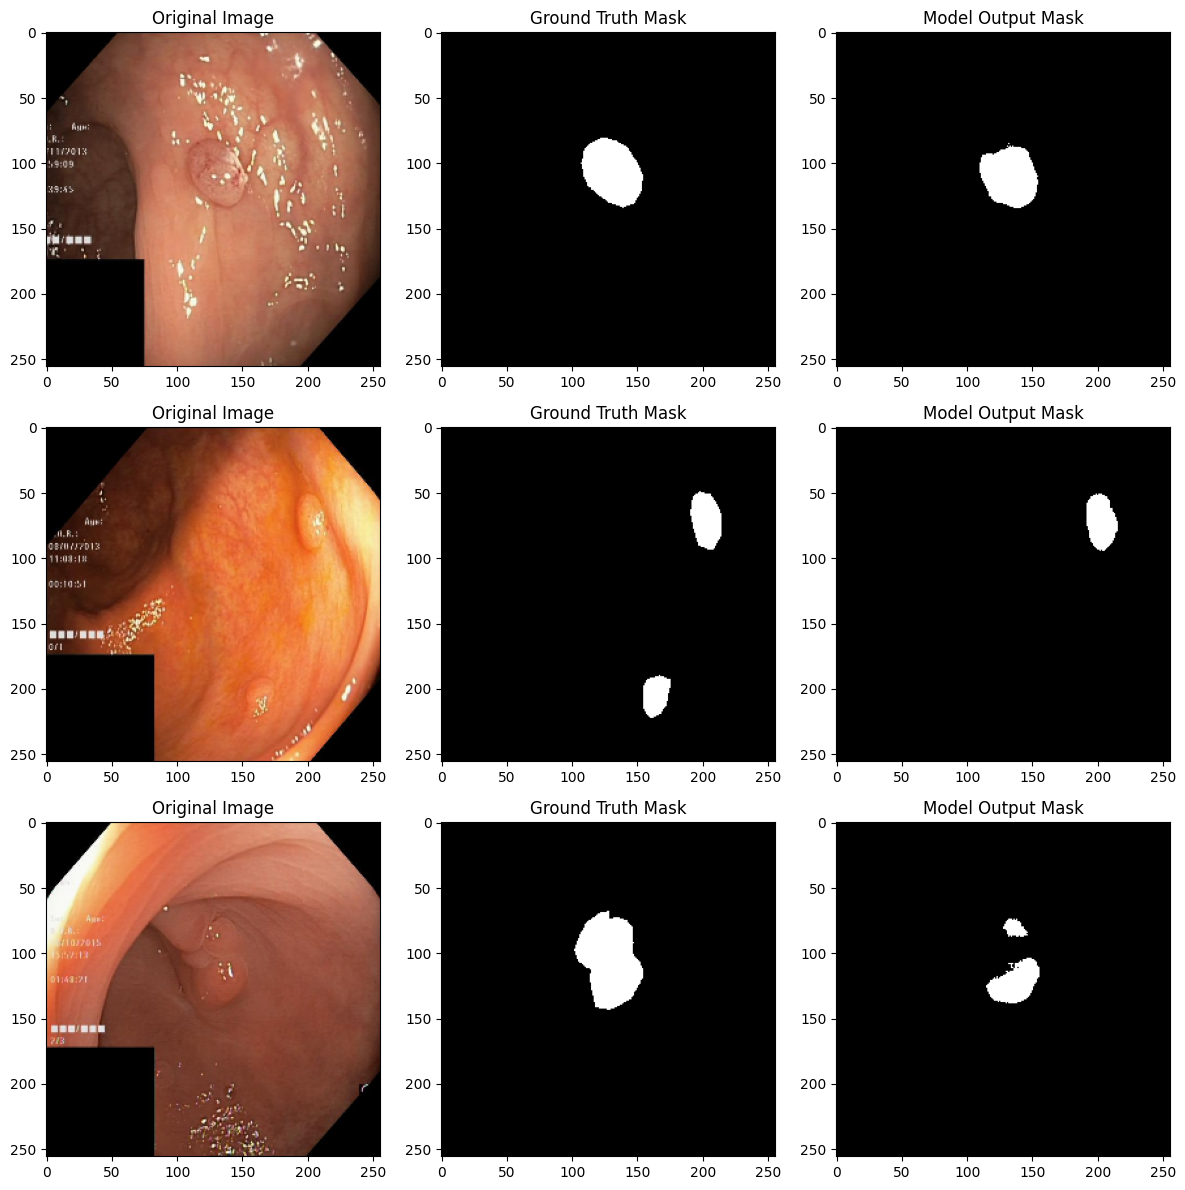

In [16]:
trainer.visualize_output_samples()

In [17]:
trainer.validate_and_save()

100%|██████████| 13/13 [00:02<00:00,  4.82it/s]



MODEL EVALUATION RESULTS
Test Loss                          : 0.4318
Average Dice Score                 : 0.8117
Average Hausdorff Distance         : 44.5371
Average IoU                        : 0.7197
Precision                          : 0.8765
Recall                             : 0.7679
F1 Score                           : 0.8186
IoU (batch avg)                    : 0.7067
Dice (batch avg)                   : 0.8250
Total Parameters                   : 10,319,211
Trainable Parameters               : 10,319,211
Average Inference Time (seconds)   : 0.048616
FPS (Frames Per Second)            : 20.57
FLOPs                              : 24,904,328,640.0
GFLOPs                             : 24.9043

Results saved to: model_comparisons/evaluation_results/SCAInceptionUNet_model_Kvasir-SEG_evaluation_results_20250908_082319.csv
Validation results saved to model_comparisons/evaluation_results/SCAInceptionUNet_model_Kvasir-SEG_evaluation_results


{'test_loss': 0.43182181968138766,
 'avg_dice_score': 0.811720833257046,
 'avg_hd_score': 44.53706191301346,
 'avg_iou': 0.7197137539649573,
 'precision': 0.8765125662887381,
 'recall': 0.7679137647711137,
 'f1': 0.8186272038275664,
 'iou_batch_avg': 0.706738815857814,
 'dice_batch_avg': 0.8249946649257953,
 'total_params': 10319211,
 'trainable_params': 10319211,
 'avg_inference_time': 0.04861598014831543,
 'fps': 20.569368280743188,
 'flops': 24904328640.0,
 'gflops': 24.90432864}